In [3]:
#!pip install pennylane



In [4]:
import torch
import pennylane as qml
from pennylane import numpy as pnp
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

### Generating synthetic toy data

In [5]:
# We generate a non-linear 2D dataset (two interleaving half-circles)
X, y = make_moons(n_samples=200, noise=0.1, random_state=42)
y = y * 2 - 1  # Shift labels from {0, 1} to {-1, 1} for quantum measurement expectations

# Scale data to match quantum rotation constraints (standardizing features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42
)

# Convert data arrays to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

### Defining the quantum circuits

In [16]:
n_qubits = 2
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    """
    A 2-qubit Variational Quantum Circuit.
    inputs: Classical data features used to rotate qubits.
    weights: Trainable parameters optimized by PyTorch gradient descent.
    """
    # Angle Embedding: Maps classical feature x[i] to quantum rotation angle Rx(x[i])
    for i in range(n_qubits):
        qml.RX(inputs[i], wires=i)

    # Strongly Entangling Layers
    num_layers = weights.shape[0]
    for layer in range(num_layers):
        for i in range(n_qubits):
            qml.Rot(weights[layer, i, 0], weights[layer, i, 1], weights[layer, i, 2], wires=i)

        # Entangle qubits
        qml.CNOT(wires=[0, 1])

    # Return as a list of measurements so TorchLayer can easily infer output shape of 1
    return [qml.expval(qml.PauliZ(0))]

### Hybrid hierarchy model configuration

In [7]:
num_layers = 3
# Initialize random parameters for optimization
weight_shapes = {"weights": (num_layers, n_qubits, 3)}
qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

# Constructing a Hybrid Model (Classical Linear pre-processing layer -> Quantum Layer)
class HybridQNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.clayer_in = torch.nn.Linear(2, 2)  # Optional classical layer
        self.vqc = qlayer                      # The PennyLane Variational Quantum Circuit

    def forward(self, x):
        x = torch.tanh(self.clayer_in(x))
        x = self.vqc(x)
        return x

model = HybridQNN()

### Training pipeline

In [19]:
# Initialize standard TorchLayer with no special arguments
qlayer = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

# Constructing a Hybrid Model (Classical Linear pre-processing layer -> Quantum Layer)
class HybridQNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.clayer_in = torch.nn.Linear(2, 2)
        self.vqc = qlayer

    def forward(self, x):
        # Pass classical features through linear and tanh activation
        x = torch.tanh(self.clayer_in(x))
        # Evaluate the VQC row-by-row to bypass PennyLane's internal batch-reshaping issues
        x = torch.stack([self.vqc(sample) for sample in x])
        # Squeeze output to shape [batch_size]
        return x.squeeze()

model = HybridQNN()

optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

print("--- Starting Hybrid Quantum-Classical Training ---")
epochs = 30
for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass
    predictions = model(X_train_t)

    # Compute Mean Squared Error Loss
    loss = loss_fn(predictions, y_train_t)

    # Backward pass and optimization step
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        # Calculate training accuracy
        with torch.no_grad():
            train_preds = torch.sign(model(X_train_t))
            accuracy = (train_preds == y_train_t).float().mean().item()
        print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {loss.item():.4f} | Train Accuracy: {accuracy * 100:.1f}%")

--- Starting Hybrid Quantum-Classical Training ---
Epoch 01/30 | Loss: 1.5729 | Train Accuracy: 26.9%
Epoch 05/30 | Loss: 1.0846 | Train Accuracy: 41.9%
Epoch 10/30 | Loss: 0.7838 | Train Accuracy: 80.0%
Epoch 15/30 | Loss: 0.5272 | Train Accuracy: 85.6%
Epoch 20/30 | Loss: 0.4181 | Train Accuracy: 85.0%
Epoch 25/30 | Loss: 0.4067 | Train Accuracy: 85.6%
Epoch 30/30 | Loss: 0.3991 | Train Accuracy: 85.6%


### Testing the model

In [20]:
with torch.no_grad():
    test_outputs = model(X_test_t)
    test_preds = torch.sign(test_outputs)
    test_accuracy = (test_preds == y_test_t).float().mean().item()

print("\n--- Evaluation Results ---")
print(f"Final Test Dataset Accuracy: {test_accuracy * 100:.2f}%")


--- Evaluation Results ---
Final Test Dataset Accuracy: 87.50%


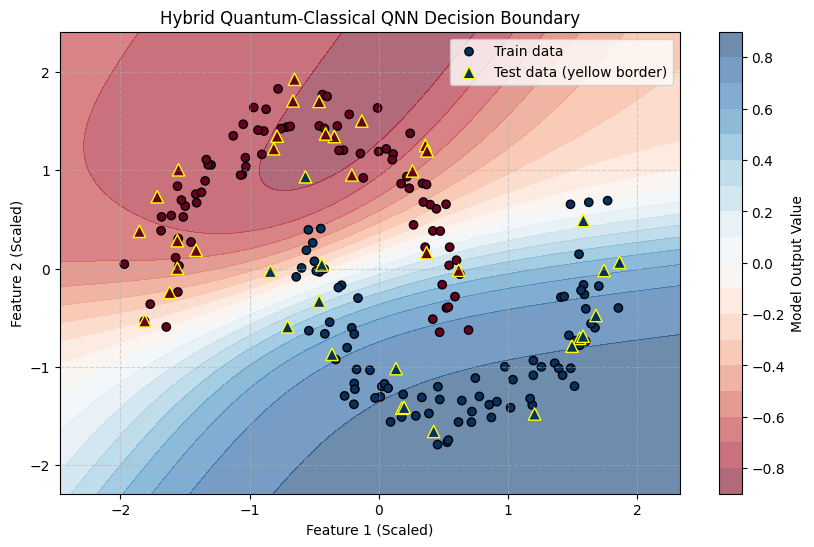

In [21]:
import numpy as np

# Create a coordinate grid spanning the feature space
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

# Convert grid points to a PyTorch tensor
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_points_t = torch.tensor(grid_points, dtype=torch.float32)

# Predict outcomes across the grid
with torch.no_grad():
    grid_predictions = model(grid_points_t)
    # Reshape the output to match the grid structure
    grid_predictions = grid_predictions.reshape(xx.shape).numpy()

# Plot the decision boundary and the dataset
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, grid_predictions, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="Model Output Value")

# Plot training and testing points
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="RdBu", edgecolors="k", marker="o", label="Train data")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="RdBu", edgecolors="yellow", marker="^", s=80, label="Test data (yellow border)")

plt.title("Hybrid Quantum-Classical QNN Decision Boundary")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Summary of QML Exploration

In this initial exploration of Quantum Machine Learning (QML), we built and evaluated a Hybrid Quantum-Classical Neural Network using PyTorch and PennyLane to classify the non-linear 2D "make_moons" dataset. By standardizing our dataset and mapping the labels to expectations of $\{-1, 1\}$, we successfully embedded the features using a 2-qubit Angle Embedding and a multi-layer parameterized Strongly Entangling Circuit. To overcome batch-dimension handling mismatches within the `TorchLayer` integration, we implemented a custom row-by-row mapping loop in the forward pass of our `HybridQNN` model. This architecture, optimized over 30 epochs with the Adam optimizer and Mean Squared Error loss, converged stably to reach a final training accuracy of 85.6% and a testing accuracy of 87.5%, outputting a smooth, curved decision boundary that cleanly separates the interleaving datasets.